# 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_regression

# 2. Upload and load the CSV

In [2]:
from google.colab import files

uploaded = files.upload()

Saving Housing.csv to Housing (1).csv


# 3. Understand the dataset

In [3]:
df = pd.read_csv("Housing.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


# 4. Basic statistical analysis

In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Number of rows: 545
Number of columns: 13

Column names:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

Data types:
price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories              int64
mainroad            object
guestroom           object
basement            object
hotwaterheating     object
airconditioning     object
parking              int64
prefarea            object
furnishingstatus    object
dtype: object


# 4. Basic statistical analysis

In [5]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [6]:
df.describe(include='object')

,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea,furnishingstatus
count,545,545,545,545,545,545,545
unique,2,2,2,2,2,2,3
top,yes,no,no,no,no,no,semi-furnished
freq,468,448,354,520,373,417,227


# 5. Check missing values

In [7]:
print(df.isnull().sum())

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [8]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

price               0.0
area                0.0
bedrooms            0.0
bathrooms           0.0
stories             0.0
mainroad            0.0
guestroom           0.0
basement            0.0
hotwaterheating     0.0
airconditioning     0.0
parking             0.0
prefarea            0.0
furnishingstatus    0.0
dtype: float64


# 6. Check duplicate records

In [9]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [10]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (545, 13)


# 7. Check unique values

In [11]:
for column in df.columns:
    print("\n", column)
    print(df[column].unique())


 price
[13300000 12250000 12215000 11410000 10850000 10150000  9870000  9800000
  9681000  9310000  9240000  9100000  8960000  8890000  8855000  8750000
  8680000  8645000  8575000  8540000  8463000  8400000  8295000  8190000
  8120000  8080940  8043000  7980000  7962500  7910000  7875000  7840000
  7700000  7560000  7525000  7490000  7455000  7420000  7350000  7343000
  7245000  7210000  7140000  7070000  7035000  7000000  6930000  6895000
  6860000  6790000  6755000  6720000  6685000  6650000  6629000  6615000
  6580000  6510000  6475000  6440000  6419000  6405000  6300000  6293000
  6265000  6230000  6195000  6160000  6125000  6107500  6090000  6083000
  6020000  5950000  5943000  5880000  5873000  5866000  5810000  5803000
  5775000  5740000  5652500  5600000  5565000  5530000  5523000  5495000
  5460000  5425000  5390000  5383000  5320000  5285000  5250000  5243000
  5229000  5215000  5145000  5110000  5075000  5040000  5033000  5005000
  4970000  4956000  4935000  4907000  49000

# 8. Separate numerical and categorical features

In [12]:
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns
categorical_features = df.select_dtypes(include=['object']).columns

print("Numerical features:")
print(list(numerical_features))

print("\nCategorical features:")
print(list(categorical_features))

Numerical features:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'parking']

Categorical features:
['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


# 9. Analyze the target variable

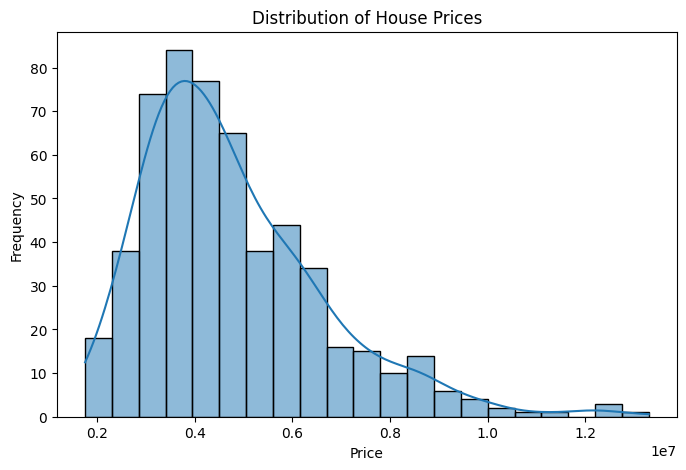

In [13]:
plt.figure(figsize=(8,5))

sns.histplot(df['price'], kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

# 10. Check correlation

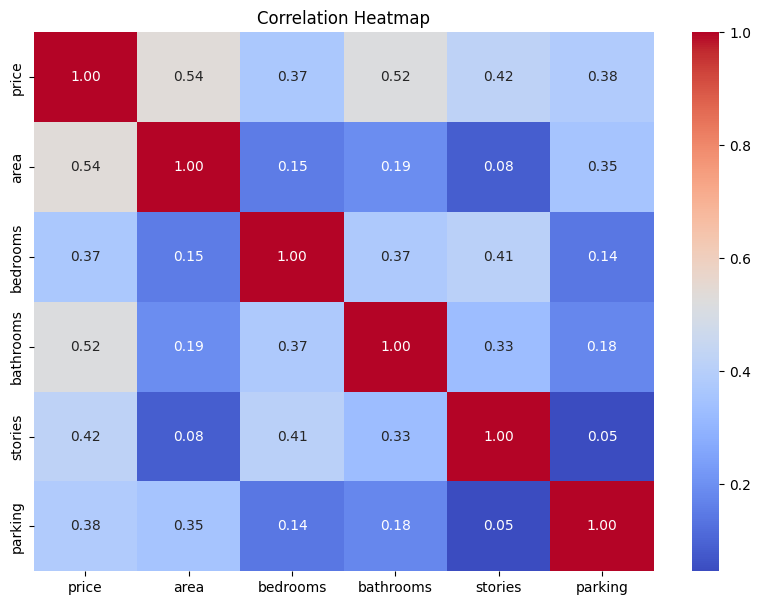

In [14]:
plt.figure(figsize=(10,7))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

# 11. Outlier detection

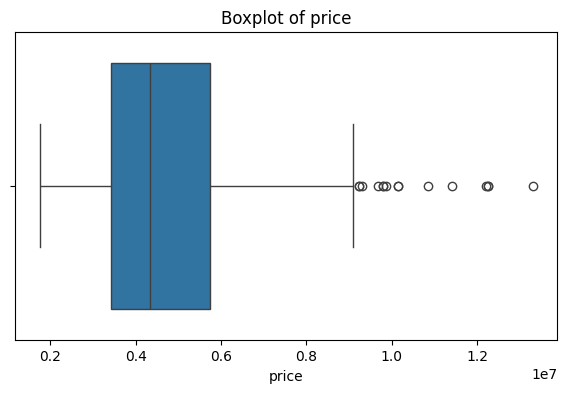

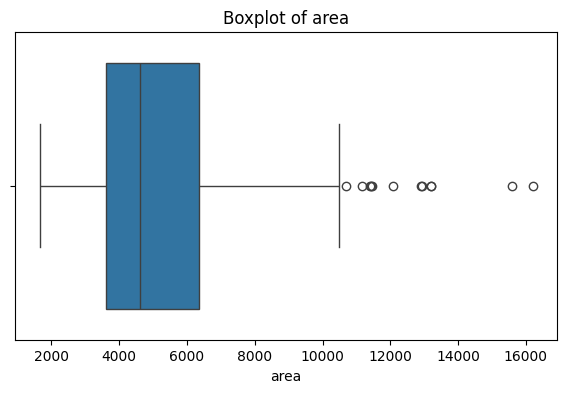

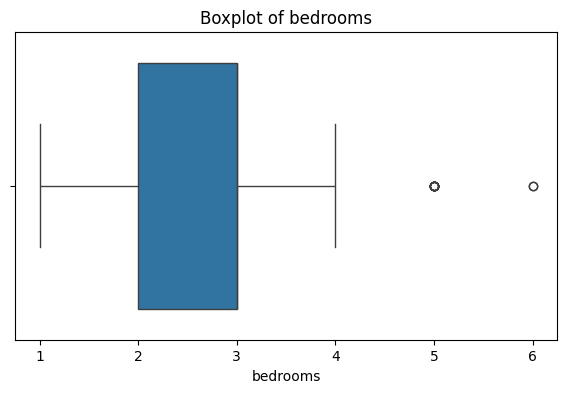

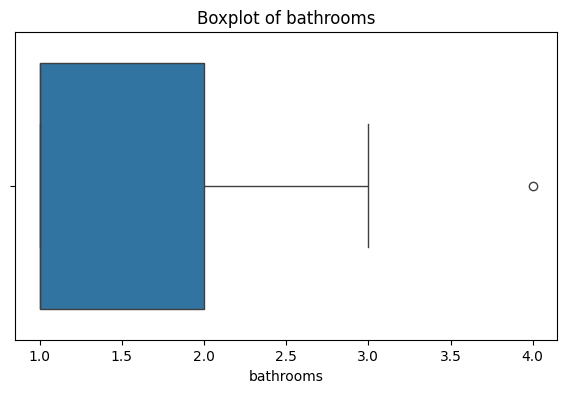

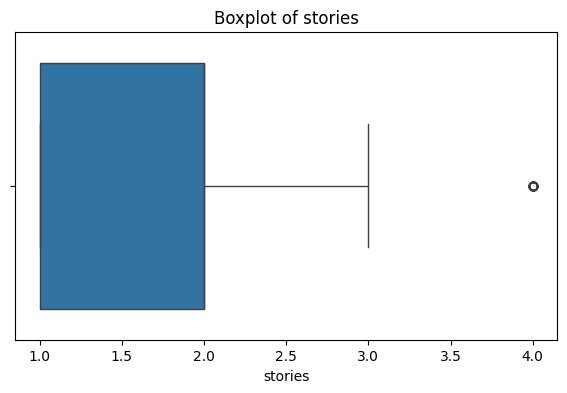

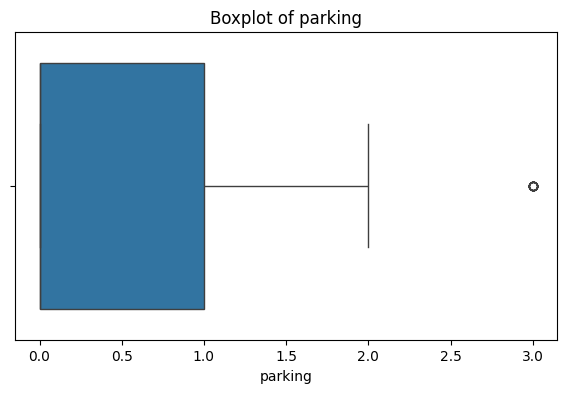

In [15]:
numerical_columns = [
    'price',
    'area',
    'bedrooms',
    'bathrooms',
    'stories',
    'parking'
]

for column in numerical_columns:

    plt.figure(figsize=(7,4))

    sns.boxplot(x=df[column])

    plt.title(f"Boxplot of {column}")

    plt.show()

# 12. Detect outliers using IQR

In [16]:
for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(column)
    print("Number of outliers:", len(outliers))
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print()

price
Number of outliers: 15
Lower bound: -35000.0
Upper bound: 9205000.0

area
Number of outliers: 12
Lower bound: -540.0
Upper bound: 10500.0

bedrooms
Number of outliers: 12
Lower bound: 0.5
Upper bound: 4.5

bathrooms
Number of outliers: 1
Lower bound: -0.5
Upper bound: 3.5

stories
Number of outliers: 41
Lower bound: -0.5
Upper bound: 3.5

parking
Number of outliers: 12
Lower bound: -1.5
Upper bound: 2.5



# 13. Handle outliers

In [17]:
df_engineered = df.copy()

for column in ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']:

    Q1 = df_engineered[column].quantile(0.25)
    Q3 = df_engineered[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_engineered[column] = df_engineered[column].clip(
        lower_bound,
        upper_bound
    )

print("Outlier capping completed.")

Outlier capping completed.


# 14. Encode binary categorical variables

In [18]:
binary_columns = [
    'mainroad',
    'guestroom',
    'basement',
    'hotwaterheating',
    'airconditioning',
    'prefarea'
]

for column in binary_columns:

    df_engineered[column] = df_engineered[column].map({
        'yes': 1,
        'no': 0
    })

df_engineered.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,1,0,0,0,1,2.0,1,furnished
1,12250000,8960,4.0,3.5,3.5,1,0,0,0,1,2.5,0,furnished
2,12250000,9960,3.0,2.0,2.0,1,0,1,0,0,2.0,1,semi-furnished
3,12215000,7500,4.0,2.0,2.0,1,0,1,0,1,2.5,1,furnished
4,11410000,7420,4.0,1.0,2.0,1,1,1,0,1,2.0,0,furnished


# 15. Encode furnishing status

In [19]:
df_engineered = pd.get_dummies(
    df_engineered,
    columns=['furnishingstatus'],
    drop_first=True,
    dtype=int
)

df_engineered.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4.0,2.0,3.0,1,0,0,0,1,2.0,1,0,0
1,12250000,8960,4.0,3.5,3.5,1,0,0,0,1,2.5,0,0,0
2,12250000,9960,3.0,2.0,2.0,1,0,1,0,0,2.0,1,1,0
3,12215000,7500,4.0,2.0,2.0,1,0,1,0,1,2.5,1,0,0
4,11410000,7420,4.0,1.0,2.0,1,1,1,0,1,2.0,0,0,0


# 16. Feature engineering — create useful new features

In [20]:
df_engineered['total_rooms'] = (
    df_engineered['bedrooms'] +
    df_engineered['bathrooms']
)

df_engineered[['bedrooms', 'bathrooms', 'total_rooms']].head()

,bedrooms,bathrooms,total_rooms
0,4.0,2.0,6.0
1,4.0,3.5,7.5
2,3.0,2.0,5.0
3,4.0,2.0,6.0
4,4.0,1.0,5.0


# 17. Feature 2: Area per bedroom

In [21]:
df_engineered['area_per_bedroom'] = (
    df_engineered['area'] /
    df_engineered['bedrooms']
)

df_engineered['area_per_bedroom'].head()

,area_per_bedroom
0,1855.0
1,2240.0
2,3320.0
3,1875.0
4,1855.0


# 18. Feature 3: Area per room

In [22]:
df_engineered['area_per_room'] = (
    df_engineered['area'] /
    df_engineered['total_rooms']
)

df_engineered['area_per_room'].head()

,area_per_room
0,1236.666667
1,1194.666667
2,1992.000000
3,1250.000000
4,1484.000000


# 19. Feature 4: Bathroom-to-bedroom ratio

In [23]:
df_engineered['bathroom_bedroom_ratio'] = (
    df_engineered['bathrooms'] /
    df_engineered['bedrooms']
)

df_engineered['bathroom_bedroom_ratio'].head()

,bathroom_bedroom_ratio
0,0.500000
1,0.875000
2,0.666667
3,0.500000
4,0.250000


# 20. Feature 5: Parking availability

In [24]:
df_engineered['has_parking'] = (
    df_engineered['parking'] > 0
).astype(int)

df_engineered[['parking', 'has_parking']].head()

,parking,has_parking
0,2.0,1
1,2.5,1
2,2.0,1
3,2.5,1
4,2.0,1


# 21. Feature 6: House amenity score

In [25]:
amenity_columns = [
    'mainroad',
    'guestroom',
    'basement',
    'hotwaterheating',
    'airconditioning',
    'prefarea'
]

df_engineered['amenity_score'] = (
    df_engineered[amenity_columns].sum(axis=1)
)

df_engineered[['amenity_score']].head()

,amenity_score
0,3
1,2
2,3
3,4
4,4


# 22. Feature 7: Area category

In [26]:
df_engineered['area_category'] = pd.qcut(
    df_engineered['area'],
    q=3,
    labels=['Small', 'Medium', 'Large']
)

df_engineered[['area', 'area_category']].head()

,area,area_category
0,7420,Large
1,8960,Large
2,9960,Large
3,7500,Large
4,7420,Large


# 23. Encode the new area category

In [27]:
df_engineered = pd.get_dummies(
    df_engineered,
    columns=['area_category'],
    drop_first=True,
    dtype=int
)

df_engineered.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,...,furnishingstatus_semi-furnished,furnishingstatus_unfurnished,total_rooms,area_per_bedroom,area_per_room,bathroom_bedroom_ratio,has_parking,amenity_score,area_category_Medium,area_category_Large
0,13300000,7420,4.0,2.0,3.0,1,0,0,0,1,...,0,0,6.0,1855.0,1236.666667,0.500000,1,3,0,1
1,12250000,8960,4.0,3.5,3.5,1,0,0,0,1,...,0,0,7.5,2240.0,1194.666667,0.875000,1,2,0,1
2,12250000,9960,3.0,2.0,2.0,1,0,1,0,0,...,1,0,5.0,3320.0,1992.000000,0.666667,1,3,0,1
3,12215000,7500,4.0,2.0,2.0,1,0,1,0,1,...,0,0,6.0,1875.0,1250.000000,0.500000,1,4,0,1
4,11410000,7420,4.0,1.0,2.0,1,1,1,0,1,...,0,0,5.0,1855.0,1484.000000,0.250000,1,4,0,1


# 24. Feature transformation — log transformation

In [28]:
df_engineered['log_price'] = np.log1p(
    df_engineered['price']
)

df_engineered[['price', 'log_price']].head()

,price,log_price
0,13300000,16.403275
1,12250000,16.321037
2,12250000,16.321037
3,12215000,16.318175
4,11410000,16.250001


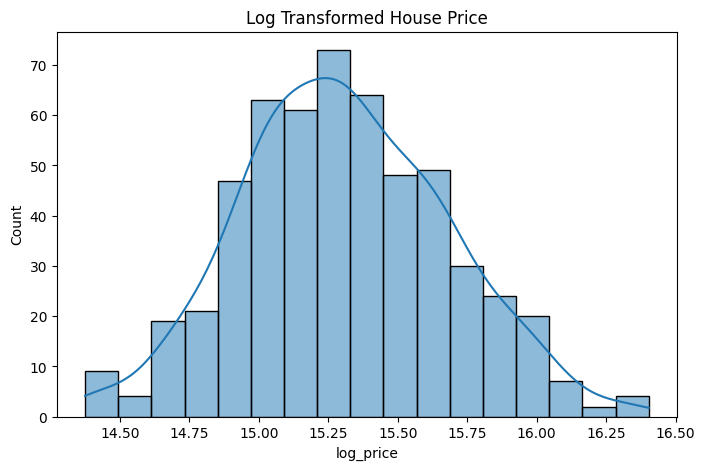

In [29]:
plt.figure(figsize=(8,5))

sns.histplot(df_engineered['log_price'], kde=True)

plt.title("Log Transformed House Price")

plt.show()

# 25. Check skewness

In [30]:
numeric_features = df_engineered.select_dtypes(
    include=np.number
).columns

skewness = df_engineered[numeric_features].skew()

print(skewness.sort_values(ascending=False))

hotwaterheating                    4.353428
guestroom                          1.688419
bathrooms                          1.502028
area_per_room                      1.303197
area_per_bedroom                   1.287823
prefarea                           1.254361
bathroom_bedroom_ratio             1.228751
price                              1.212239
area                               0.807511
airconditioning                    0.795748
furnishingstatus_unfurnished       0.741509
area_category_Medium               0.732609
stories                            0.730828
parking                            0.722931
area_category_Large                0.706135
basement                           0.628590
total_rooms                        0.604009
amenity_score                      0.472994
furnishingstatus_semi-furnished    0.339635
has_parking                        0.195961
log_price                          0.140863
bedrooms                           0.124515
mainroad                        

# 26. Log-transform highly skewed input features

In [31]:
df_engineered['log_area'] = np.log1p(
    df_engineered['area']
)

df_engineered[['area', 'log_area']].head()

,area,log_area
0,7420,8.912069
1,8960,9.100637
2,9960,9.206433
3,7500,8.922792
4,7420,8.912069


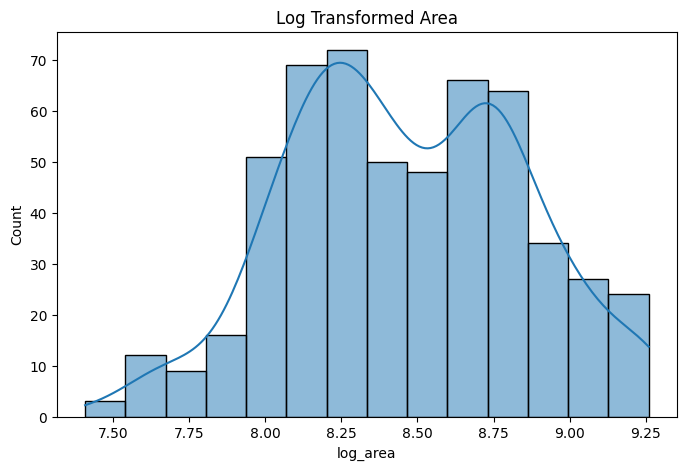

In [32]:
plt.figure(figsize=(8,5))

sns.histplot(df_engineered['log_area'], kde=True)

plt.title("Log Transformed Area")

plt.show()

# 27. Check the engineered dataset

In [33]:
print("Original number of columns:", df.shape[1])
print("Engineered number of columns:", df_engineered.shape[1])

print("\nNew columns:")
new_columns = [
    col for col in df_engineered.columns
    if col not in df.columns
]

print(new_columns)

Original number of columns: 13
Engineered number of columns: 24

New columns:
['furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished', 'total_rooms', 'area_per_bedroom', 'area_per_room', 'bathroom_bedroom_ratio', 'has_parking', 'amenity_score', 'area_category_Medium', 'area_category_Large', 'log_price', 'log_area']


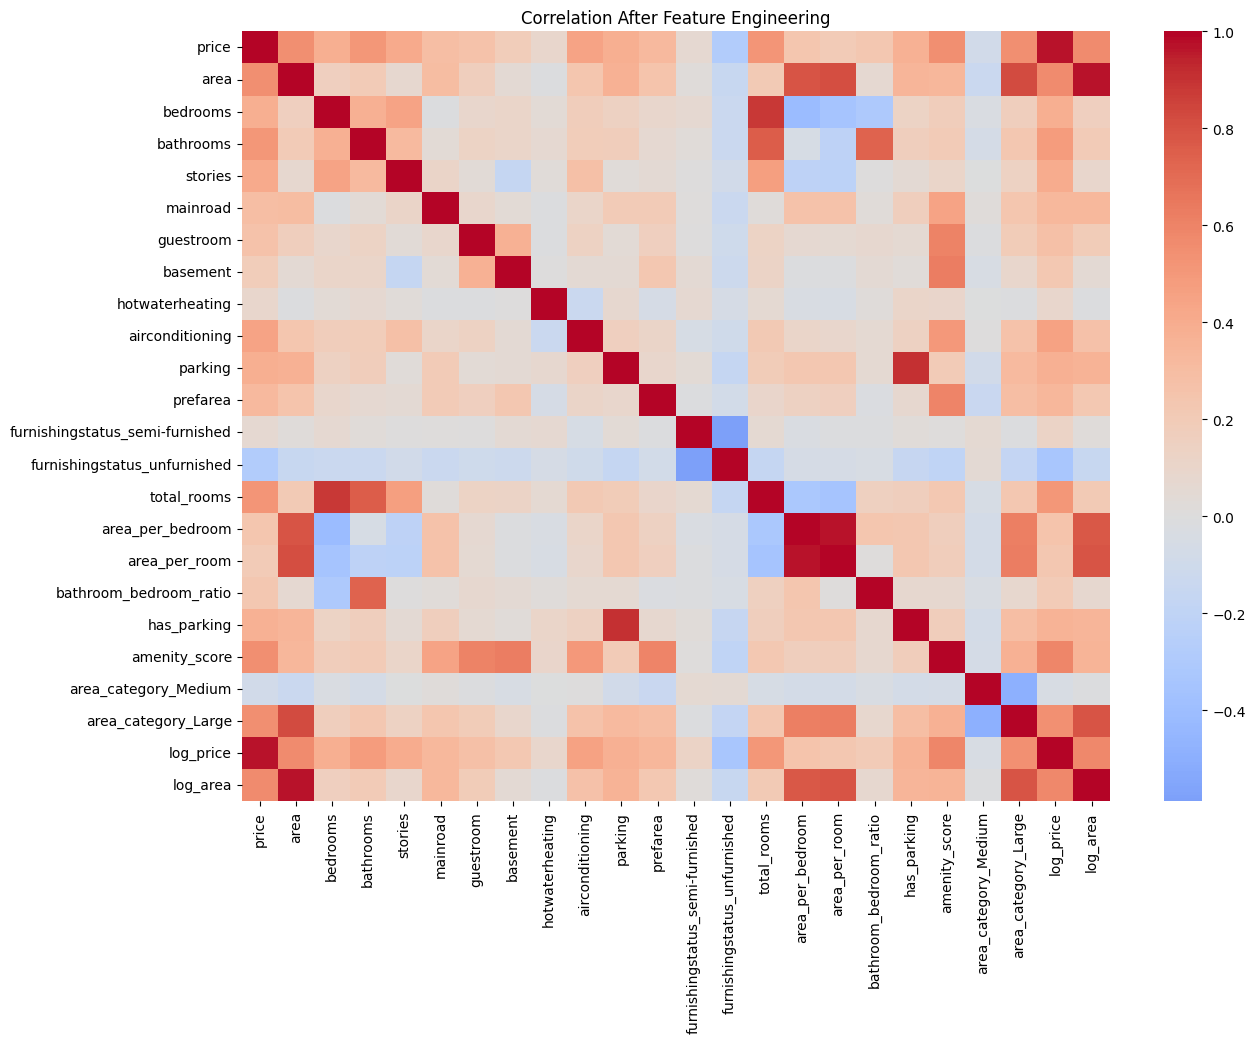

In [34]:
plt.figure(figsize=(14,10))

corr = df_engineered.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0
)

plt.title("Correlation After Feature Engineering")

plt.show()

# 29. Prepare X and y

In [35]:
X = df_engineered.drop(
    columns=['price', 'log_price']
)

y = df_engineered['price']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (545, 22)
y shape: (545,)


# 30. Train-test split

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (436, 22)
Testing data: (109, 22)


# 31. Feature scaling

In [37]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [38]:
scaler.transform(X_test)

array([[ 0.39631809,  1.50546715,  1.56126601, ...,  1.40213637,
        -0.69860905,  0.57009617],
       [ 0.69354644,  0.08164139,  1.56126601, ..., -0.71319739,
         1.43141575,  0.82036978],
       [-0.52508977, -1.34218438, -0.56264032, ...,  1.40213637,
        -0.69860905, -0.40849428],
       ...,
       [ 0.44585615,  1.50546715,  1.56126601, ..., -0.71319739,
         1.43141575,  0.61352785],
       [ 0.44585615,  0.08164139,  1.56126601, ..., -0.71319739,
         1.43141575,  0.61352785],
       [ 0.49539421,  0.08164139,  1.56126601, ..., -0.71319739,
         1.43141575,  0.65624174]])

# 32. Convert scaled data back to DataFrame

In [39]:
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

X_train_scaled_df.head()

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,...,furnishingstatus_unfurnished,total_rooms,area_per_bedroom,area_per_room,bathroom_bedroom_ratio,has_parking,amenity_score,area_category_Medium,area_category_Large,log_area
46,0.445856,0.081641,1.561266,2.276137,0.407155,-0.466773,-0.746420,-0.230521,1.501243,0.391688,...,-0.676900,0.800772,0.234224,-0.103528,1.486071,1.106567,0.011324,-0.713197,1.431416,0.613528
93,1.040313,0.081641,1.561266,-0.969107,0.407155,-0.466773,1.339728,-0.230521,1.501243,2.202032,...,-0.676900,0.800772,0.735030,0.343457,1.486071,1.106567,0.834188,-0.713197,1.431416,1.084677
335,-0.636055,-1.342184,-0.562640,-0.969107,0.407155,-0.466773,1.339728,-0.230521,1.501243,1.598584,...,-0.676900,-1.220279,0.119039,0.030568,0.384310,1.106567,0.834188,-0.713197,-0.698609,-0.555885
412,-1.233484,0.081641,-0.562640,0.328990,0.407155,-0.466773,1.339728,-0.230521,-0.666115,-0.815209,...,1.477322,-0.209753,-1.180552,-1.123211,-0.717450,-0.903696,0.834188,-0.713197,-0.698609,-1.537323
471,-0.668750,0.081641,-0.562640,0.328990,0.407155,-0.466773,-0.746420,-0.230521,-0.666115,-0.815209,...,1.477322,-0.209753,-0.704787,-0.592417,-0.717450,-0.903696,-0.811540,-0.713197,-0.698609,-0.600966


# 33. Feature selection

In [40]:
selector = SelectKBest(
    score_func=f_regression,
    k=10
)

X_train_selected = selector.fit_transform(
    X_train_scaled,
    y_train
)

X_test_selected = selector.transform(
    X_test_scaled
)

selected_features = X_train.columns[
    selector.get_support()
]

print("Selected features:")
print(selected_features.tolist())

Selected features:
['area', 'bedrooms', 'bathrooms', 'stories', 'airconditioning', 'parking', 'total_rooms', 'amenity_score', 'area_category_Large', 'log_area']


# 34. View feature scores

In [41]:
feature_scores = pd.DataFrame({
    'Feature': X_train.columns,
    'Score': selector.scores_
})

feature_scores = feature_scores.sort_values(
    by='Score',
    ascending=False
)

feature_scores

,Feature,Score
20,area_category_Large,218.971490
21,log_area,203.375113
0,area,188.281525
18,amenity_score,187.142862
2,bathrooms,168.510827
13,total_rooms,165.297224
8,airconditioning,123.439412
1,bedrooms,75.732831
3,stories,75.568623
9,parking,72.721755


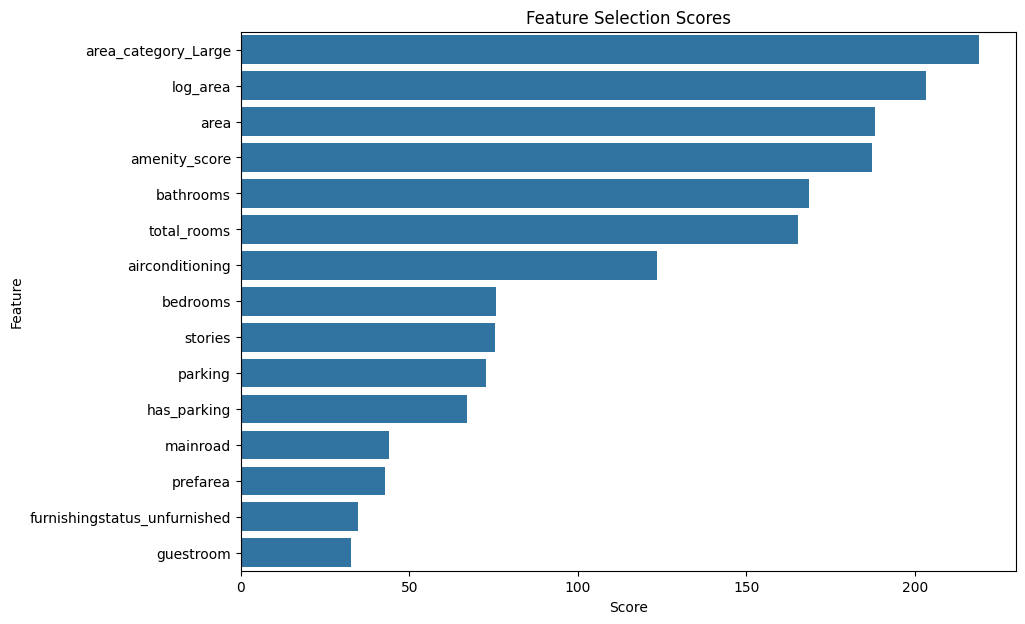

In [42]:
plt.figure(figsize=(10,7))

sns.barplot(
    data=feature_scores.head(15),
    x='Score',
    y='Feature'
)

plt.title("Feature Selection Scores")

plt.show()

# 35. Final engineered datase

In [43]:
print("Final dataset shape:")
print(df_engineered.shape)

print("\nFinal columns:")
print(df_engineered.columns.tolist())

df_engineered.head()

Final dataset shape:
(545, 24)

Final columns:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished', 'total_rooms', 'area_per_bedroom', 'area_per_room', 'bathroom_bedroom_ratio', 'has_parking', 'amenity_score', 'area_category_Medium', 'area_category_Large', 'log_price', 'log_area']


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,...,total_rooms,area_per_bedroom,area_per_room,bathroom_bedroom_ratio,has_parking,amenity_score,area_category_Medium,area_category_Large,log_price,log_area
0,13300000,7420,4.0,2.0,3.0,1,0,0,0,1,...,6.0,1855.0,1236.666667,0.500000,1,3,0,1,16.403275,8.912069
1,12250000,8960,4.0,3.5,3.5,1,0,0,0,1,...,7.5,2240.0,1194.666667,0.875000,1,2,0,1,16.321037,9.100637
2,12250000,9960,3.0,2.0,2.0,1,0,1,0,0,...,5.0,3320.0,1992.000000,0.666667,1,3,0,1,16.321037,9.206433
3,12215000,7500,4.0,2.0,2.0,1,0,1,0,1,...,6.0,1875.0,1250.000000,0.500000,1,4,0,1,16.318175,8.922792
4,11410000,7420,4.0,1.0,2.0,1,1,1,0,1,...,5.0,1855.0,1484.000000,0.250000,1,4,0,1,16.250001,8.912069


# 36. Check for missing/infinite values after feature engineering

In [44]:
print("Missing values:")
print(df_engineered.isnull().sum())

print("\nInfinite values:")

print(
    np.isinf(
        df_engineered.select_dtypes(
            include=np.number
        )
    ).sum()
)

Missing values:
price                              0
area                               0
bedrooms                           0
bathrooms                          0
stories                            0
mainroad                           0
guestroom                          0
basement                           0
hotwaterheating                    0
airconditioning                    0
parking                            0
prefarea                           0
furnishingstatus_semi-furnished    0
furnishingstatus_unfurnished       0
total_rooms                        0
area_per_bedroom                   0
area_per_room                      0
bathroom_bedroom_ratio             0
has_parking                        0
amenity_score                      0
area_category_Medium               0
area_category_Large                0
log_price                          0
log_area                           0
dtype: int64

Infinite values:
price                              0
area                        

# 37. Save the feature-engineered dataset

In [45]:
df_engineered.to_csv(
    "Housing_feature_engineered.csv",
    index=False
)

print("Feature-engineered dataset saved successfully.")

Feature-engineered dataset saved successfully.


In [46]:
from google.colab import files

files.download("Housing_feature_engineered.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Workflow

                  Housing.csv
                       │
                       ▼
              Load Dataset
                       │
                       ▼
              Understand Data
                       │
                       ▼
             Data Type Analysis
                       │
                       ▼
             Missing Value Check
                       │
                       ▼
             Duplicate Detection
                       │
                       ▼
             Outlier Detection
                       │
                       ▼
            Outlier Treatment
                       │
                       ▼
          Categorical Encoding
                       │
                       ▼
          Feature Construction
                       │
             ┌─────────┼──────────┐
             ▼         ▼          ▼
        Total Rooms  Area/Room  Amenity Score
             │         │          │
             └─────────┼──────────┘
                       ▼
              Feature Transformation
                       │
                 ┌─────┴─────┐
                 ▼           ▼
             Log Area    Log Price
                       │
                       ▼
                Feature Analysis
                       │
                       ▼
                 Feature Scaling
                       │
                       ▼
                 Feature Selection
                       │
                       ▼
               Train/Test Split
                       │
                       ▼
            Feature-Engineered Data
                       │
                       ▼
                 ML Algorithm